#  SurveyLens — Week 2: Clean Responses and Engineer Features

**SkillMe | Data Science Virtual Internship | Week 2**  
**Dataset:** UCI Adult Census Income (1994 census-derived training subset)  
**Status:** Week 2 analysis completed; notebook outputs and data-quality checks are included.

> **Connection to Week 1:** This project continues with the same public dataset and rechecks the same `education` → `hours_per_week` group comparison. The Week 1 project remains unchanged.

## Objectives and official deliverables

1. Build `clean_categories(df)` with `.str.strip()`, `.str.lower()` and a mapping dictionary.
2. Document and apply a justified missing-value strategy.
3. Engineer at least one bucketed feature with `pd.cut()`.
4. One-hot encode 2–3 categorical columns using `pd.get_dummies()`.
5. Re-run the Week 1 group comparison on the cleaned dataset.
6. Show category counts **before and after** standardization/consolidation.
7. Save and reload **`data/survey_clean.csv`**; check shape, schema and absence of missing data in cleaned fields.
8. **Stretch goal:** automatic allow-list validation.

**Research integrity:** The UCI Adult `workclass` labels are already fairly consistent. To meaningfully reduce unique categories, we explicitly **consolidate related employment classes** (e.g., government subtypes → `government`). This is intentional analytical grouping, **not** the correction of fabricated typos. The original data are preserved separately in `df_raw`.

## 1. Environment and reproducibility

Only standard, commonly available Colab libraries are required. Outputs are saved in a dedicated `SurveyLens_Week2_Project/` folder in the notebook runtime. The official data are downloaded when the notebook executes; no generated or synthetic source rows are used in the final analysis.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
PROJECT_DIR = Path("SurveyLens_Week2_Project")
DATA_DIR = PROJECT_DIR / "data"
FIGURES_DIR = PROJECT_DIR / "outputs"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Python data tools ready. Project directory:", PROJECT_DIR.resolve())

Python data tools ready. Project directory: /content/SurveyLens_Week2_Project


## 2. Load the original Week 1 dataset and preserve it

Use the **same** UCI Adult training-data URL and 15 column names as the approved Week 1 analysis. `?` means missing in this source. `df_raw` will never be modified in place.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
COLUMNS = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"
]

try:
    df_raw = pd.read_csv(
        DATA_URL, header=None, names=COLUMNS,
        na_values="?", skipinitialspace=True
    )
except Exception as exc:
    raise RuntimeError(
        "Could not download the official UCI Adult dataset. "
        "Make sure Google Colab has an internet connection, then rerun this cell."
    ) from exc

assert df_raw.shape == (32561, 15), (
    f"Unexpected source dataset dimensions: {df_raw.shape}. "
    "Check that the original UCI training dataset was loaded."
)
assert df_raw["occupation"].isna().sum() == 1843, "Original source differs from Week 1."
print("Original dataset shape:", df_raw.shape)
print("Original missing values:")
display(df_raw.isna().sum().loc[lambda x: x.gt(0)].to_frame("missing_rows"))
print("Raw 'workclass' unique values (including missing):")
print(df_raw["workclass"].unique())
display(df_raw.head())

Original dataset shape: (32561, 15)
Original missing values:


,missing_rows
workclass,1836
occupation,1843
native_country,583


Raw 'workclass' unique values (including missing):
['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' 'Local-gov' nan
 'Self-emp-inc' 'Without-pay' 'Never-worked']


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 3. Missing-value treatment — decisions and reasons

| Field | Week 1 missing values | Week 2 treatment | Why |
|---|---:|---|---|
| `workclass` | 1,836 | Fill missing with `unknown` | Employment status cannot be inferred safely; retain the record. |
| `occupation` | 1,843 | Fill missing with `unknown` | Unknown is more honest than guessing a person's job or dropping data. |
| `native_country` | 583 | Fill missing with `unknown` | Avoid inventing origin; preserve sample size for later analysis. |

**No numerical imputation is required:** The six original numeric columns have no missing values in this training dataset. We do **not** use a median fill simply to demonstrate `.fillna()`.

We standardize whitespace/case in selected text fields, then consolidate `workclass` into broader groups for interpretable comparisons. For example, `self-emp-inc` and `self-emp-not-inc` are distinct original labels: grouping them as `self-employed` **loses detail intentionally**, and that limitation should be remembered in later analyses.

## 4. `clean_categories(df)` — reproducible, documented text cleaning

1. Inspect actual `workclass` labels from the source instead of inventing inconsistent spelling.
2. Use `.str.strip()` and `.str.lower()` and collapse repeated whitespace.
3. Apply an explicit mapping to create a **reduced** `workclass_group` field.
4. Keep a standardized detailed `workclass` field so later analyses can recover the original distinctions.

In [3]:
WORKCLASS_GROUP_MAP = {
    "private": "private sector",
    "self-emp-not-inc": "self-employed",
    "self-emp-inc": "self-employed",
    "federal-gov": "government",
    "local-gov": "government",
    "state-gov": "government",
    "without-pay": "unpaid",
    "never-worked": "never worked",
}
EXPECTED_WORKCLASS_GROUPS = set(WORKCLASS_GROUP_MAP.values()) | {"unknown"}


def normalized_text(series):
    """Trim, lowercase, and normalize repeated whitespace; preserve missing values."""
    return (series.astype("string")
                  .str.strip()
                  .str.lower()
                  .str.replace(r"\s+", " ", regex=True))


def clean_categories(frame):
    """Return a NEW frame with normalized workclass detail and grouped labels."""
    result = frame.copy(deep=True)
    raw_normalized = normalized_text(result["workclass"])

    unmapped = set(raw_normalized.dropna().unique()) - set(WORKCLASS_GROUP_MAP)
    if unmapped:
        raise ValueError(f"Unmapped workclass values: {sorted(unmapped)}")

    result["workclass"] = raw_normalized.fillna("unknown")
    result["workclass_group"] = raw_normalized.map(WORKCLASS_GROUP_MAP).fillna("unknown")
    return result


df_clean = clean_categories(df_raw)
# Fill missing selected categorical responses without inventing a real response.
for field in ["occupation", "native_country"]:
    df_clean[field] = normalized_text(df_clean[field]).fillna("unknown")

print("Original workclass labels (with missing):")
display(df_raw["workclass"].value_counts(dropna=False).to_frame("count"))
print("Cleaned workclass groups (unknown includes missing):")
display(df_clean["workclass_group"].value_counts(dropna=False).to_frame("count"))

Original workclass labels (with missing):


,count
workclass,
Private,22696
Self-emp-not-inc,2541
Local-gov,2093
NaN,1836
State-gov,1298
Self-emp-inc,1116
Federal-gov,960
Without-pay,14
Never-worked,7


Cleaned workclass groups (unknown includes missing):


,count
workclass_group,
private sector,22696
government,4351
self-employed,3657
unknown,1836
unpaid,14
never worked,7


## 5. Before/after unique-category comparison

We compare **unique values including missing/`unknown`** in both versions so the counts have the same basis. A reduction comes from explicit **grouping**, not from discovering genuine inconsistent spellings in the UCI source.

,version,unique_categories_including_missing
0,original workclass,9
1,cleaned workclass_group,6


Category count: 9 → 6 (reduction: 3).


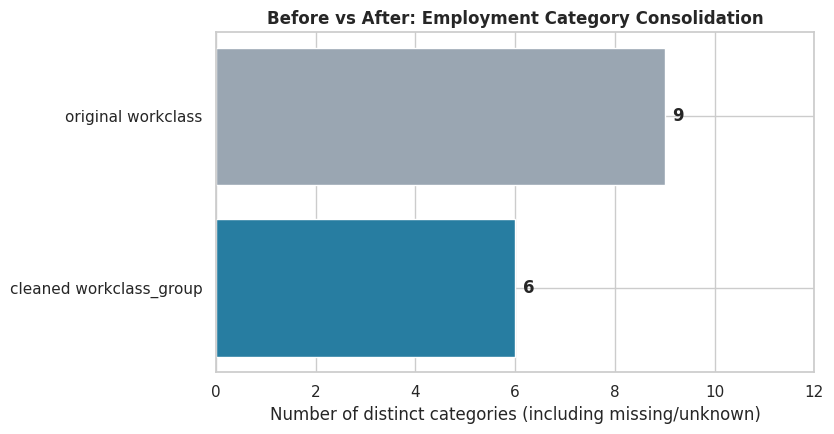

In [4]:
raw_n = df_raw["workclass"].nunique(dropna=False)
clean_n = df_clean["workclass_group"].nunique(dropna=False)
category_comparison = pd.DataFrame({
    "version": ["original workclass", "cleaned workclass_group"],
    "unique_categories_including_missing": [raw_n, clean_n],
})
display(category_comparison)
print(f"Category count: {raw_n} → {clean_n} (reduction: {raw_n - clean_n}).")
assert clean_n < raw_n, "Expected a meaningful reduction in workclass categories."

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.barh(category_comparison["version"], category_comparison["unique_categories_including_missing"],
               color=["#9AA6B2", "#277DA1"])
ax.invert_yaxis()
ax.set_xlabel("Number of distinct categories (including missing/unknown)")
ax.set_title("Before vs After: Employment Category Consolidation", weight="bold")
ax.set_xlim(0, raw_n + 3)
for bar in bars:
    ax.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height()/2,
            str(int(bar.get_width())), va="center", weight="bold")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "01_workclass_before_after.png", dpi=220, bbox_inches="tight")
plt.show()

## 6. Feature engineering: bucket continuous ages

The original numeric `age` is retained. We add an **age band**, not a career-seniority label: age alone does not establish someone's professional experience. The bin edges cover all observed adult ages.

In [5]:
AGE_BINS = [16, 24, 34, 44, 54, 64, np.inf]
AGE_LABELS = ["17-24", "25-34", "35-44", "45-54", "55-64", "65+"]
df_clean["age_band"] = pd.cut(
    df_clean["age"], bins=AGE_BINS, labels=AGE_LABELS, include_lowest=True
)

print("Age bands:")
display(df_clean["age_band"].value_counts(sort=False).to_frame("records"))
assert df_clean["age_band"].notna().all(), "Some ages fell outside the bins."
assert set(df_clean["age_band"].dropna().astype(str).unique()) <= set(AGE_LABELS)

Age bands:


,records
age_band,
17-24,5570
25-34,8479
35-44,8151
45-54,5853
55-64,3172
65+,1336


## 7. Missing values after cleaning — chart and audit

The selected fields should have zero missing values. We check the raw and cleaned counts on the **same three fields**. All other columns are also checked so hidden missingness does not go unnoticed.

,before_missing,after_missing
workclass,1836,0
occupation,1843,0
native_country,583,0


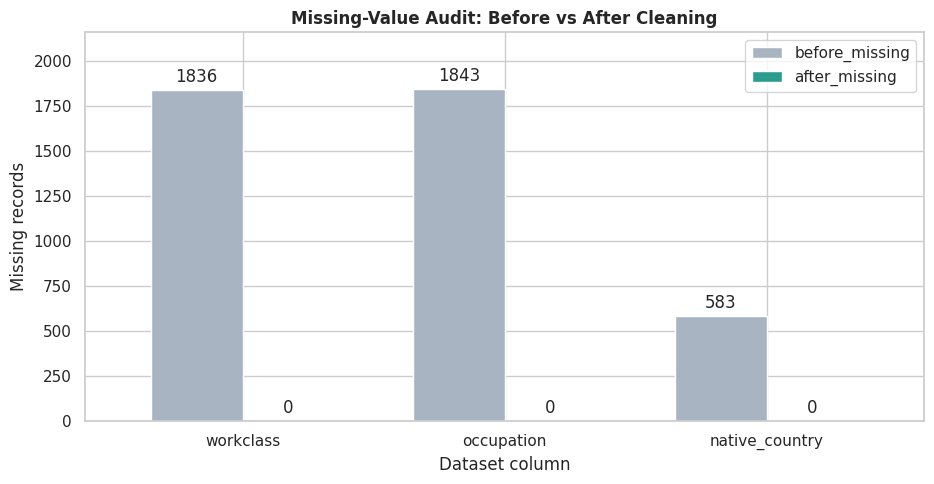

In [6]:
TARGET_MISSING_COLUMNS = ["workclass", "occupation", "native_country"]
before_missing = df_raw[TARGET_MISSING_COLUMNS].isna().sum()
after_missing = df_clean[TARGET_MISSING_COLUMNS].isna().sum()
missing_audit = pd.DataFrame({"before_missing": before_missing, "after_missing": after_missing})
display(missing_audit)
assert (after_missing == 0).all(), "Missing values remain in the cleaned target fields."
assert df_clean.isna().sum().sum() == 0, "Unexpected missing values remain in output."

ax = missing_audit.plot(kind="bar", figsize=(9.5, 5), color=["#A9B4C2", "#2A9D8F"], width=0.7)
ax.set_title("Missing-Value Audit: Before vs After Cleaning", weight="bold")
ax.set_ylabel("Missing records")
ax.set_xlabel("Dataset column")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="")
for group in ax.containers:
    ax.bar_label(group, padding=3)
ax.set_ylim(0, before_missing.max() * 1.17)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_missing_values_before_after.png", dpi=220, bbox_inches="tight")
plt.show()

## 8. One-hot encode three categorical columns

`pd.get_dummies()` creates numeric indicator columns for `workclass_group`, `education` and `marital_status`. This encoded version is stored separately so the human-readable cleaned CSV retains categorical labels.

**Modeling note:** `income` is deliberately **not** among the encoded inputs here because it could become a target in Week 3. Feature selection, leakage checks and validation will be handled when the actual modeling task is available.

In [7]:
ENCODE_COLUMNS = ["workclass_group", "education", "marital_status"]
df_encoded = pd.get_dummies(
    df_clean, columns=ENCODE_COLUMNS, dtype=int, prefix_sep="__"
)
encoded_columns = [c for c in df_encoded.columns if "__" in c]
print("Encoded source columns:", ENCODE_COLUMNS)
print("Number of dummy columns:", len(encoded_columns))
print("Cleaned dataframe shape:", df_clean.shape)
print("Encoded dataframe shape:", df_encoded.shape)
display(df_encoded[encoded_columns[:min(12, len(encoded_columns))]].head())
assert len(encoded_columns) > len(ENCODE_COLUMNS)
assert all(df_encoded[c].isin([0, 1]).all() for c in encoded_columns)

Encoded source columns: ['workclass_group', 'education', 'marital_status']
Number of dummy columns: 29
Cleaned dataframe shape: (32561, 17)
Encoded dataframe shape: (32561, 43)


,workclass_group__government,workclass_group__never worked,workclass_group__private sector,workclass_group__self-employed,workclass_group__unknown,workclass_group__unpaid,education__10th,education__11th,education__12th,education__1st-4th,education__5th-6th,education__7th-8th
0,1,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,1,0,0,0,0,0,0,0,0
2,0,0,1,0,0,0,0,0,0,0,0,0
3,0,0,1,0,0,0,0,1,0,0,0,0
4,0,0,1,0,0,0,0,0,0,0,0,0


## 9. Re-run the exact Week 1 comparison

Week 1 compared **mean `hours_per_week` grouped by `education`**. Cleaning categorical employment fields must not accidentally alter these numerical statistics. We compare both the group means **and group sizes** and assert equality; then add a new group comparison using `workclass_group`.

In [8]:
week1_hours = df_raw.groupby("education")["hours_per_week"].agg(["count", "mean"])
week2_hours = df_clean.groupby("education")["hours_per_week"].agg(["count", "mean"])
comparison = (week1_hours.rename(columns={"count": "week1_n", "mean": "week1_mean"})
    .join(week2_hours.rename(columns={"count": "week2_n", "mean": "week2_mean"})))
comparison["mean_difference"] = comparison["week2_mean"] - comparison["week1_mean"]
display(comparison.sort_values("week1_mean", ascending=False).round(3))
assert comparison["week1_n"].equals(comparison["week2_n"]), "Group sizes changed!"
assert np.allclose(comparison["week1_mean"], comparison["week2_mean"]), "Week 1 group averages changed!"
print("PASS: Every Week 1 education-group count and average is preserved.")

new_group_stats = df_clean.groupby("workclass_group")["hours_per_week"].agg(["count", "mean"]).sort_values("count", ascending=False)
print("New grouped analysis: average weekly hours by cleaned workclass group")
display(new_group_stats.round(2))

,week1_n,week1_mean,week2_n,week2_mean,mean_difference
education,,,,,
Prof-school,576,47.425,576,47.425,0.0
Doctorate,413,46.973,413,46.973,0.0
Masters,1723,43.836,1723,43.836,0.0
Bachelors,5355,42.614,5355,42.614,0.0
Assoc-voc,1382,41.611,1382,41.611,0.0
HS-grad,10501,40.575,10501,40.575,0.0
Assoc-acdm,1067,40.504,1067,40.504,0.0
7th-8th,646,39.367,646,39.367,0.0
5th-6th,333,38.898,333,38.898,0.0


PASS: Every Week 1 education-group count and average is preserved.
New grouped analysis: average weekly hours by cleaned workclass group


,count,mean
workclass_group,,
private sector,22696,40.27
government,4351,40.49
self-employed,3657,45.76
unknown,1836,31.92
unpaid,14,32.71
never worked,7,28.43


## 10. Additional visualization: standardized employment-group distribution

The frequencies below are descriptive counts in this historical dataset. The `unknown` group is explicitly shown rather than removed without explanation.

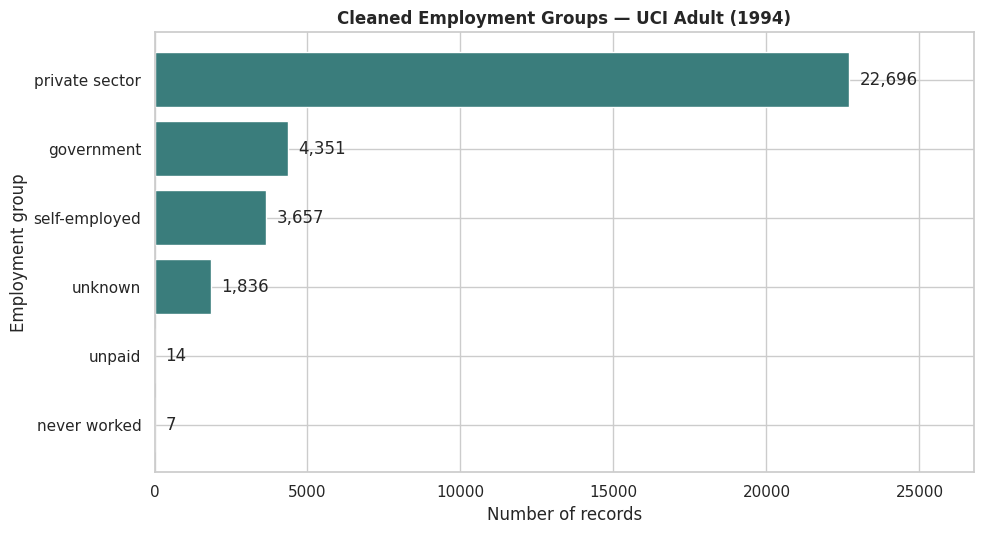

In [9]:
workclass_freq = df_clean["workclass_group"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(workclass_freq.index, workclass_freq.values, color="#3A7D7C")
ax.set_title("Cleaned Employment Groups — UCI Adult (1994)", weight="bold")
ax.set_xlabel("Number of records")
ax.set_ylabel("Employment group")
ax.set_xlim(0, workclass_freq.max() * 1.18)
for i, n in enumerate(workclass_freq.values):
    ax.text(n + workclass_freq.max() * 0.015, i, f"{n:,}", va="center")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "03_cleaned_workclass_distribution.png", dpi=220, bbox_inches="tight")
plt.show()

## 11. Stretch goal: automated allow-list and quality tests

The checks below fail loudly if unknown categories slip into `workclass_group`, if any bucket label is unexpected, if cleaning changes the row count, or if the chosen fields remain missing.

In [10]:
def validate_cleaned_dataset(raw, cleaned):
    allowed_workclass = set(WORKCLASS_GROUP_MAP.values()) | {"unknown"}
    assert set(cleaned["workclass_group"].unique()) <= allowed_workclass, "Unexpected workclass group"
    assert set(cleaned["age_band"].dropna().astype(str).unique()) <= set(AGE_LABELS), "Unexpected age band"
    assert len(cleaned) == len(raw), "Cleaning removed or added records"
    assert cleaned[TARGET_MISSING_COLUMNS + ["workclass_group", "age_band"]].notna().all().all(), "Missing cleaned fields"
    assert cleaned["age"].equals(raw["age"]), "Original ages were modified"
    assert cleaned["hours_per_week"].equals(raw["hours_per_week"]), "Original weekly hours were modified"
    return True

assert validate_cleaned_dataset(df_raw, df_clean)
print("PASS: workclass allow-list")
print("PASS: age-band allow-list")
print("PASS: record counts, missingness, and original numerical features")

PASS: workclass allow-list
PASS: age-band allow-list
PASS: record counts, missingness, and original numerical features


## 12. Save both data products and reload the required CSV

The **official Week 2 deliverable** is **`data/survey_clean.csv`**. For future work we also export `data/survey_encoded.csv` as a supplemental output; it does **not** replace the readable cleaned dataset. Both are generated from the real UCI data during execution.

In [11]:
CLEAN_CSV = DATA_DIR / "survey_clean.csv"
ENCODED_CSV = DATA_DIR / "survey_encoded.csv"

df_clean.to_csv(CLEAN_CSV, index=False)
df_encoded.to_csv(ENCODED_CSV, index=False)

reloaded = pd.read_csv(CLEAN_CSV)
assert reloaded.shape == df_clean.shape, "Reloaded CSV has unexpected dimensions"
assert reloaded.columns.tolist() == df_clean.columns.tolist(), "Reloaded columns differ"
assert reloaded[TARGET_MISSING_COLUMNS + ["workclass_group", "age_band"]].isna().sum().sum() == 0
assert set(reloaded["age_band"].unique()) == set(df_clean["age_band"].astype(str).unique())
assert reloaded["age"].equals(df_clean["age"])

print("PASS: CSV saved and reloaded successfully")
print("Clean CSV:", CLEAN_CSV, "→", reloaded.shape, "→", f"{CLEAN_CSV.stat().st_size:,} bytes")
print("Encoded CSV:", ENCODED_CSV, "→", df_encoded.shape, "→", f"{ENCODED_CSV.stat().st_size:,} bytes")
display(reloaded.head())

PASS: CSV saved and reloaded successfully
Clean CSV: SurveyLens_Week2_Project/data/survey_clean.csv → (32561, 17) → 4,191,273 bytes
Encoded CSV: SurveyLens_Week2_Project/data/survey_encoded.csv → (32561, 43) → 4,817,019 bytes


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,workclass_group,age_band
0,39,state-gov,77516,Bachelors,13,Never-married,adm-clerical,Not-in-family,White,Male,2174,0,40,united-states,<=50K,government,35-44
1,50,self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,exec-managerial,Husband,White,Male,0,0,13,united-states,<=50K,self-employed,45-54
2,38,private,215646,HS-grad,9,Divorced,handlers-cleaners,Not-in-family,White,Male,0,0,40,united-states,<=50K,private sector,35-44
3,53,private,234721,11th,7,Married-civ-spouse,handlers-cleaners,Husband,Black,Male,0,0,40,united-states,<=50K,private sector,45-54
4,28,private,338409,Bachelors,13,Married-civ-spouse,prof-specialty,Wife,Black,Female,0,0,40,cuba,<=50K,private sector,25-34


## 13. Data-driven findings and limitations

The next cell prints findings from **executed** results, rather than relying on hand-written or guessed counts. Category consolidation makes employment groups more interpretable at the cost of discarding some detailed class distinctions *in the added grouped feature*. The detailed `workclass` remains separately available.

**Limitations:** The dataset contains historical US Census-derived records. An `unknown` label represents missing information; it is not a real occupation, employment class, or country. Education-group differences in hours worked are **descriptive associations**, not evidence of causation. The original unmodified `df_raw` is retained in memory for comparisons.

In [12]:
most_common_group = df_clean["workclass_group"].value_counts().idxmax()
most_common_n = int(df_clean["workclass_group"].value_counts().max())
print("WEEK 2 VERIFIED FINDINGS")
print("------------------------")
print(f"Original workclass categories incl. missing: {raw_n}")
print(f"Cleaned employment groups incl. unknown: {clean_n}")
print(f"Most frequent cleaned employment group: {most_common_group} ({most_common_n:,} records)")
for col in TARGET_MISSING_COLUMNS:
    print(f"{col}: {before_missing[col]:,} missing → {after_missing[col]:,} missing")
print(f"New age bands: {', '.join(AGE_LABELS)}")
print(f"Dummy-encoded columns: {len(encoded_columns)} from {len(ENCODE_COLUMNS)} source fields")
print("Week 1 education-to-hours grouped comparison: unchanged (all groups).")

WEEK 2 VERIFIED FINDINGS
------------------------
Original workclass categories incl. missing: 9
Cleaned employment groups incl. unknown: 6
Most frequent cleaned employment group: private sector (22,696 records)
workclass: 1,836 missing → 0 missing
occupation: 1,843 missing → 0 missing
native_country: 583 missing → 0 missing
New age bands: 17-24, 25-34, 35-44, 45-54, 55-64, 65+
Dummy-encoded columns: 29 from 3 source fields
Week 1 education-to-hours grouped comparison: unchanged (all groups).
